<a href="https://colab.research.google.com/github/William2Git/FPGA-CNN-Number-Detector/blob/main/ECE_241_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:

!pip -q install torchview graphviz

Loading the dataset

In [3]:
torch.manual_seed(42)

digits = load_digits()

# Convert pixel intensities from 0-16 to 0-255 (8-bit)
pixels = np.rint(digits.images * 255 / 16).astype(np.uint8)

# Convert to floats in [0, 1] for training
X = pixels.astype(np.float32) / 255.0

# Add channel dimension: (1797, 1, 8, 8)
X = X[:, None, :, :]

# Correct digit labels (0-9)
y = digits.target.astype(np.int64)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train),
                  torch.from_numpy(y_train)),
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_test),
                  torch.from_numpy(y_test)),
    batch_size=64
)

print(X_train.shape)


(1437, 1, 8, 8)


Defining CNN structure

TinyCNN(
  (conv): Conv2d(1, 4, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=36, out_features=10, bias=True)
)


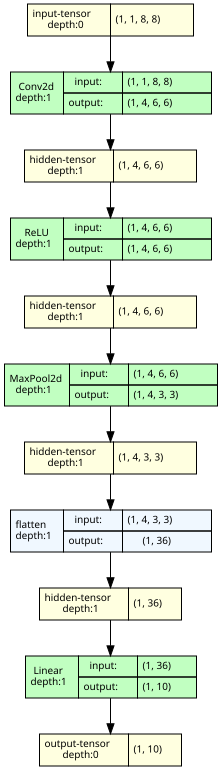

In [4]:

import torch.nn as nn

class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels=1,
            out_channels=4,
            kernel_size=3
        )

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)

        self.fc = nn.Linear(36, 10)

    def forward(self, x):
        x = self.conv(x)
        x = self.relu(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

model = TinyCNN()
print(model)

#visual
from torchview import draw_graph

graph = draw_graph(
    model,
    input_size=(1, 1, 8, 8),
    expand_nested=True,
    show_shapes=True,
    hide_inner_tensors=False,
    device="cpu"
)

display(graph.visual_graph)


Training (Forward + backward propagation)

In [5]:

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

epochs = 30

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        predictions = model(images)
        loss = loss_fn(predictions, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}: "
              f"Loss = {total_loss/len(X_train):.4f}")


Epoch 5: Loss = 0.5345
Epoch 10: Loss = 0.2455
Epoch 15: Loss = 0.1785
Epoch 20: Loss = 0.1361
Epoch 25: Loss = 0.1147
Epoch 30: Loss = 0.0945


Testing

In [6]:

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        correct += (predicted == labels).sum().item()
        total += len(labels)

print(f"Test accuracy: {100 * correct / total:.2f}%")

Test accuracy: 96.39%


Download weights and bias

In [7]:
import torch
from google.colab import files

# Save all trained weights and biases
torch.save(model.state_dict(), "tinycnn_digits.pth")

# Download the file to your computer
files.download("tinycnn_digits.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The following is visual (below)

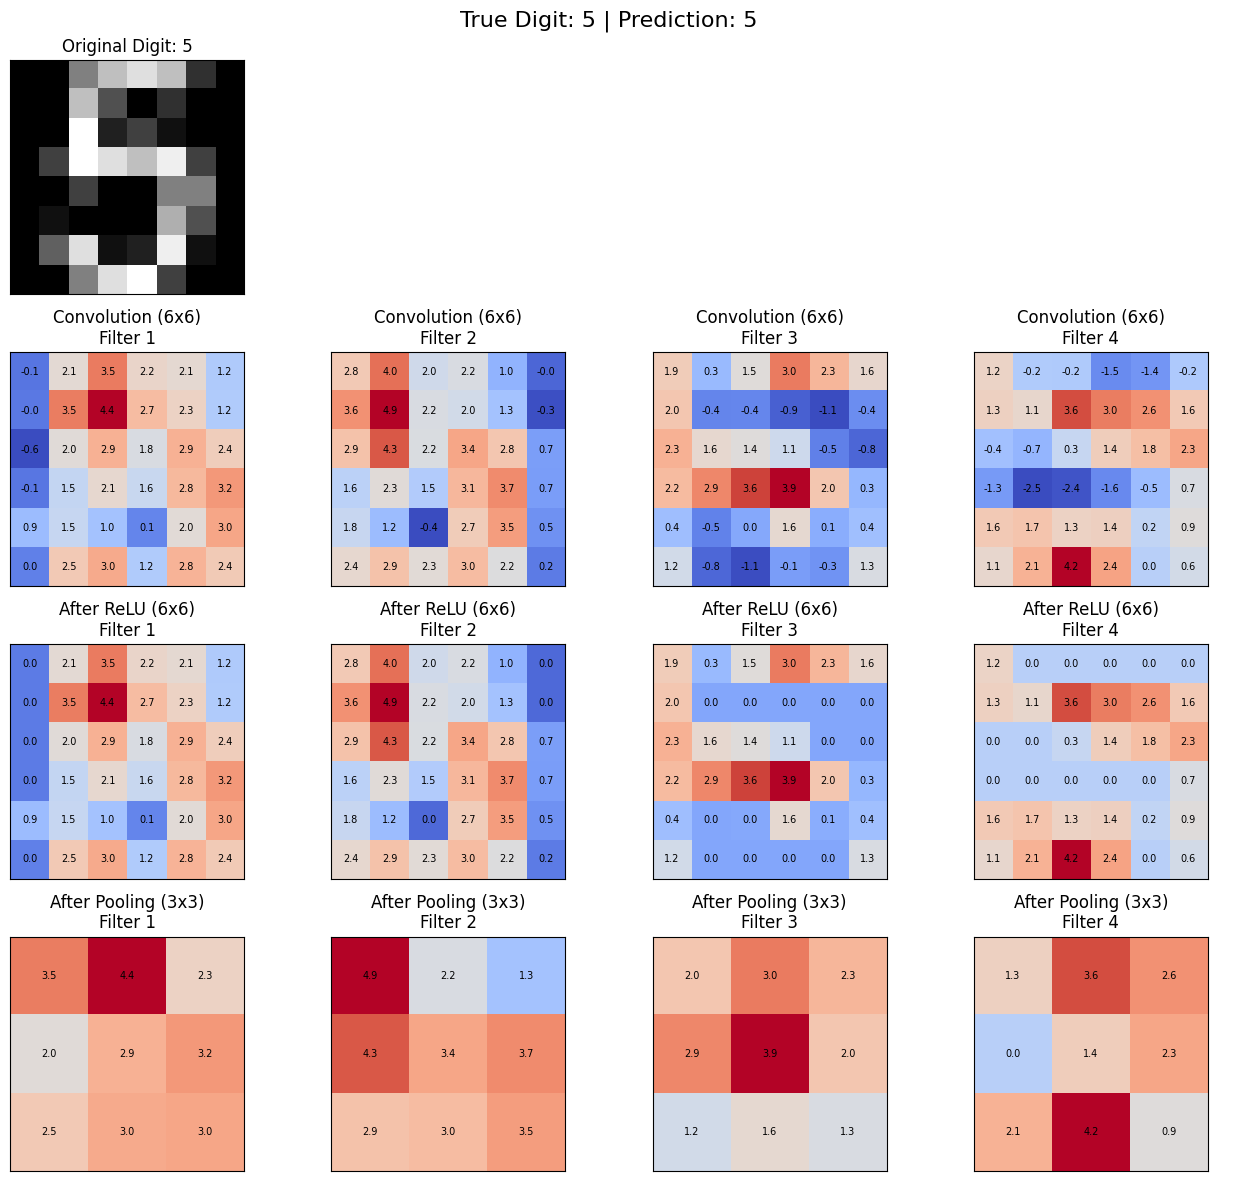

In [8]:

import matplotlib.pyplot as plt
import torch

model.eval()

# Take one test image
images, labels = next(iter(test_loader))
image = images[0:1]
label = labels[0].item()

with torch.no_grad():
    conv = model.conv(image)
    relu = model.relu(conv)
    pool = model.pool(relu)

    prediction = model(image).argmax(dim=1).item()

# Visualize every stage
fig, axes = plt.subplots(4, 4, figsize=(13, 12))

axes[0, 0].imshow(image[0, 0].cpu().numpy(), cmap="gray")
axes[0, 0].set_title(f"Original Digit: {label}")

for j in range(1, 4):
    axes[0, j].axis("off")

stages = [
    ("Convolution (6x6)", conv),
    ("After ReLU (6x6)", relu),
    ("After Pooling (3x3)", pool)
]

for col in range(4):
    # Same color scale for all stages of this filter
    vmin = min(0, conv[0, col].min().item())
    vmax = max(0.01, conv[0, col].max().item())

    for row, (name, tensor) in enumerate(stages, start=1):
        data = tensor[0, col].cpu().numpy()

        axes[row, col].imshow(
            data,
            cmap="coolwarm",
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest"
        )
        axes[row, col].set_title(f"{name}\nFilter {col+1}")

        # Show numerical values
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                axes[row, col].text(
                    j, i, f"{data[i,j]:.1f}",
                    ha="center", va="center",
                    fontsize=7, color="black"
                )

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    f"True Digit: {label} | Prediction: {prediction}",
    fontsize=16
)
plt.tight_layout()

# Save figure
plt.savefig("cnn_feature_maps.png", dpi=200, bbox_inches="tight")
plt.show()


Actual digit: 5

Pixel values (0-255):
[[  0   0 128 191 223 191  48   0]
 [  0   0 191  80   0  48   0   0]
 [  0   0 255  32  64  16   0   0]
 [  0  64 255 223 191 239  64   0]
 [  0   0  64   0   0 128 128   0]
 [  0  16   0   0   0 175  80   0]
 [  0  96 223  16  32 239  16   0]
 [  0   0 128 223 255  64   0   0]]


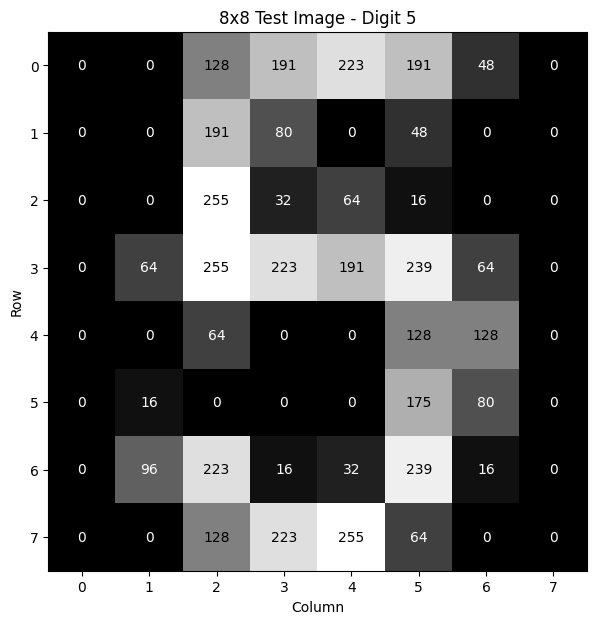

In [9]:
# Choose which test image to display
image_index = 0

# Get the selected image and its correct digit label
image = X_test[image_index, 0]  # Shape: (8, 8)
label = y_test[image_index]

# Convert normalized [0,1] values back to 8-bit [0,255]
pixels = np.rint(image * 255).astype(np.uint8)

# Print the 8x8 matrix
print("Actual digit:", label)
print("\nPixel values (0-255):")
print(pixels)

# Display image with pixel values
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(pixels, cmap="gray", vmin=0, vmax=255)

# Write each pixel's value inside its square
for row in range(8):
    for col in range(8):
        value = pixels[row, col]

        ax.text(
            col, row, str(value),
            ha="center",
            va="center",
            color="white" if value < 128 else "black",
            fontsize=10
        )

ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.set_title(f"8x8 Test Image - Digit {label}")

plt.show()